## **Thông tin bắt buộc**

MSSV: 24694721  

HoTen: Vo Van Tuan

SoMay: 11



**số máy chỉ điền 2 con số, vd: 02**

## **Coding 10đ**

* import thư viện

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

### **Discovery & Structuring (1.9đ)**


* đọc file csv, in 3 dòng cuối tiên (0.2đ)


In [3]:
df = pd.read_csv("postings.csv", low_memory=False)
df.tail(3)

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
123851,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
123852,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
123853,35982263,NaN,Service Technician (duplicate job_id),Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


* đọc thông tin data (0.15đ)

In [4]:
df.info

<bound method DataFrame.info of           job_id            company_name  \
0         921716   Corcoran Sawyer Smith   
1        1829192                     NaN   
2       10998357  The National Exemplar    
3       23221523  Abrams Fensterman, LLP   
4       35982263                     NaN   
...          ...                     ...   
123849    921716   Corcoran Sawyer Smith   
123850   1829192                     NaN   
123851  10998357  The National Exemplar    
123852  23221523  Abrams Fensterman, LLP   
123853  35982263                     NaN   

                                                    title  \
0                                   Marketing Coordinator   
1                       Mental Health Therapist/Counselor   
2                             Assitant Restaurant Manager   
3       Senior Elder Law / Trusts and Estates Associat...   
4                                      Service Technician   
...                                                   ...   
123849      

* in thông tin số dòng và số cột (0.15đ)

In [8]:

print("so dong la :", df.shape[0])
print("so cot la :" ,df.shape[1])

so dong la : 123854
so cot la : 31


* in ra các giá trị formatted_work_type trong bộ data (0.15đ)

In [9]:
df["formatted_work_type"].unique()

array(['Full-time', 'Internship', 'Contract', 'Part-time', 'Temporary',
       'Volunteer', 'Other'], dtype=object)

* đổi tên cột normalized_salary --> salary và formatted_experience_level --> experience_level (0.2đ)

In [13]:
df = df.rename(columns={
    "normalized_salary" : "salary" , 
    "formatted_experience_level": "experience_level" 
})


* in lại danh sách các cột sau khi rename (0.15đ)

In [14]:
df.columns

Index(['job_id', 'company_name', 'title', 'description', 'max_salary',
       'pay_period', 'location', 'company_id', 'views', 'med_salary',
       'min_salary', 'formatted_work_type', 'applies', 'original_listed_time',
       'remote_allowed', 'job_posting_url', 'application_url',
       'application_type', 'expiry', 'closed_time', 'experience_level',
       'skills_desc', 'listed_time', 'posting_domain', 'sponsored',
       'work_type', 'currency', 'compensation_type', 'salary', 'zip_code',
       'fips'],
      dtype='object')

* Tạo dataframe df_profile bao gồm dtype, nunique, missing_count, missing_percentage. Sắp xếp giảm dần theo missing_percentage. (0.5đ)


In [15]:
df_profile = pd.DataFrame({
    "dtype": df.dtypes,
    "nunique": df.nunique(),
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
}).sort_values("missing_percentage", ascending=False)
df_profile

,dtype,nunique,missing_count,missing_percentage
closed_time,float64,698,122781,99.133657
skills_desc,object,2212,121412,98.028324
med_salary,float64,1417,117574,94.929514
remote_allowed,float64,1,108608,87.690345
applies,float64,274,100533,81.170572
max_salary,float64,5321,94056,75.941027
min_salary,float64,4612,94056,75.941027
currency,object,6,87776,70.870541
compensation_type,object,1,87776,70.870541
salary,float64,7259,87776,70.870541


* tìm số dòng thỏa điều kiện formatted_work_type là Full-time và salary từ 100000 trở lên (0.2đ)

In [16]:
len(df[(df["formatted_work_type"] == "Full-time") & (df["salary"] >= 100000)])

11702

* cho biết số dòng có remote_allowed bằng 1 và application_type là OffsiteApply (0.2đ)

In [17]:
len(df[(df["remote_allowed"] == 1) & (df["application_type"] == "OffsiteApply")])

7283

### **Cleaning**

#### **Duplicated & missing data (3.05đ)**


Duplicate count (0.4đ)
* In số dòng trùng cả bản ghi.
* In số job_id bị lặp.


In [ ]:

print(df.duplicated().sum())
print(df["job_id"].duplicated().sum())


3
5


(123854, 31)

* xoá số dòng duplicated cả bản ghi (0.25đ)


In [23]:
df = df.drop_duplicates()
df.shape

(123851, 31)

* xoá số dòng duplicated số job_id (0.25đ)


In [24]:
df = df.drop_duplicates(subset="job_id")
df.shape

(123849, 31)

df2 missing table (0.4đ)
* Kiểm tra dữ liệu có missing không?
* Nếu có, tạo df2 gồm 3 cột: column_name, missing_count, missing_percentage
* Sắp xếp df2 giảm dần theo missing_count
* Chỉ giữ các dòng có missing_count khác 0

In [25]:
print(df.isnull().values.any())

df2 = pd.DataFrame({
    "column_name": df.columns,
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (df.isnull().mean() * 100).values
})
df2 = df2.sort_values("missing_count", ascending=False)
df2 = df2[df2["missing_count"] != 0]
df2

True


,column_name,missing_count,missing_percentage
19,closed_time,122776,99.133622
21,skills_desc,121410,98.030666
9,med_salary,117569,94.929309
14,remote_allowed,108603,87.689848
12,applies,100529,81.170619
4,max_salary,94056,75.944093
10,min_salary,94056,75.944093
26,currency,87776,70.873402
27,compensation_type,87776,70.873402
28,salary,87776,70.873402


Missing-value bar chart (0.4đ)
* Sử dụng barchart để vẽ df2 với x là missing_count, y là column_name. Trong đó xlabel là số lượng thiếu, ylabel là tên cột

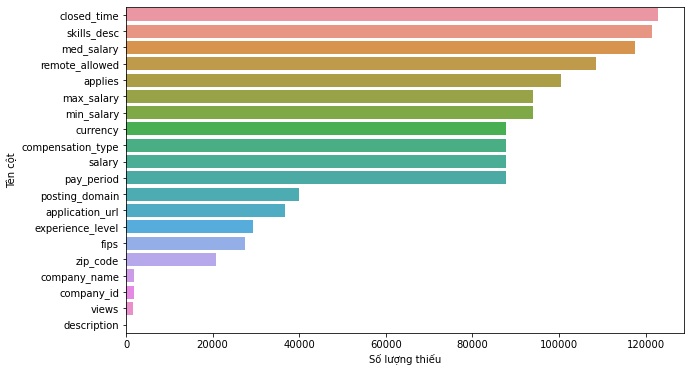

In [26]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df2, x="missing_count", y="column_name")
plt.xlabel("Số lượng thiếu")
plt.ylabel("Tên cột")
plt.show()

* tạo ra 1 cột salary_missing, nếu salary bị thiếu thì bằng 1, ngược lại bằng 0, gợi ý isna() (0.25đ)


In [27]:
df["salary_missing"] = df["salary"].isna().astype(int)

* salary_missing_by_work = Nhóm theo formatted_work_type, tính mean của cột salary_missing rồi nhân 100 để ra tỷ lệ thiếu (%). Sắp xếp tăng dần và đổi tên thành salary_missing_pct. (0.25đ)


In [28]:
salary_missing_by_work = (
    df.groupby("formatted_work_type")["salary_missing"].mean() * 100
).sort_values(ascending=True).rename("salary_missing_pct")

salary_missing_by_work

formatted_work_type
Temporary     66.890756
Contract      68.234712
Full-time     70.517336
Other         71.663244
Internship    74.872838
Part-time     76.237624
Volunteer     98.576512
Name: salary_missing_pct, dtype: float64

* Vẽ bar chart tỷ lệ thiếu salary theo formatted_work_type. xlabel là tỷ lệ thiếu (%), ylabel là tên nhóm. (0.25đ)


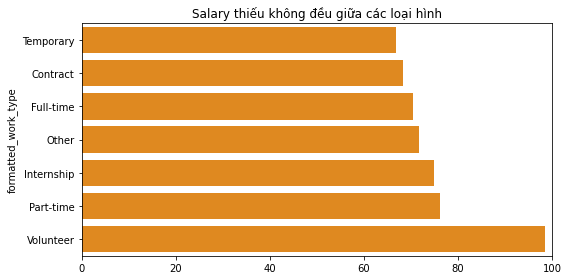

In [29]:
plt.figure(figsize=(8, 4))
sns.barplot(
    x=salary_missing_by_work.values,
    y=salary_missing_by_work.index,
    color="darkorange",
)

plt.title("Salary thiếu không đều giữa các loại hình")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


Fill with mode/mean/median (0.6đ)
* company_name: điền mode.
* views và applies: điền median.
* experience_level: ô trống điền nhãn Unknown.
* Tạo remote_flag từ remote_allowed, ô trống điền 0.
* salary: không điền.


In [30]:
df["company_name"] = df["company_name"].fillna(df["company_name"].mode()[0])
df["views"] = df["views"].fillna(df["views"].median())
df["applies"] = df["applies"].fillna(df["applies"].median())
df["experience_level"] = df["experience_level"].fillna("Unknown")
df["remote_flag"] = df["remote_allowed"].fillna(0).astype(int)

In [31]:
# kiểm tra lại sau xử lý missing data
df[["company_name", "views", "applies", "experience_level", "salary"]].isnull().sum()

company_name            0
views                   0
applies                 0
experience_level        0
salary              87776
dtype: int64

#### **Outlier (2.5đ)**

* df2_1 chỉ chứa views và salary. Hiển thị 2 dòng (0.2đ)


In [32]:
df2_1 = df[["views", "salary"]]
df2_1.head(2)

,views,salary
0,20.0,38480.0
1,1.0,83200.0


df3 with concat (0.5đ)
* Tạo dataframe df3 bằng CONCAT
* df3 gồm các cột Q1, Q3, IQR, lower_bound, upper_bound, outlier_count
* Trong đó cột Q1 là 22%, Q3 = 78%

In [33]:
Q1 = df2_1.quantile(0.22)
Q3 = df2_1.quantile(0.78)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outlier_count = ((df2_1 < lower_bound) | (df2_1 > upper_bound)).sum()

df3 = pd.concat([Q1, Q3, IQR, lower_bound, upper_bound, outlier_count], axis=1)
df3.columns = ["Q1", "Q3", "IQR", "lower_bound", "upper_bound", "outlier_count"]
df3

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
views,3.0,8.00,5.00,-4.50,15.5,16902
salary,48880.0,130169.44,81289.44,-73054.16,252103.6,720


df4 outlier filter (0.4đ)
* df4 lọc lại dữ liệu, loại các dòng có ít nhất một cột số trong df2_1 nằm ngoài [lower_bound, upper_bound]

In [34]:
is_outlier = ((df2_1 < df3["lower_bound"]) | (df2_1 > df3["upper_bound"])).any(axis=1)
df4 = df[~is_outlier]

In [36]:
df4.shape

(106379, 33)

df5 clip (0.3đ)
* Tạo df5 từ df bằng clip kéo ngưỡng về chặn trên chặn dưới

In [40]:
df5 = df.copy()
df5[["views", "salary"]] = df5[["views", "salary"]].clip(
    lower=df3["lower_bound"],
    upper=df3["upper_bound"],
    axis=1
)

In [41]:
df5.shape


(123849, 33)

Histogram of salary (0.25đ)
* vẽ histogram cho cột salary trong df4
* title là "phân phối salary"
* xlabel là "salary (USD/year)"

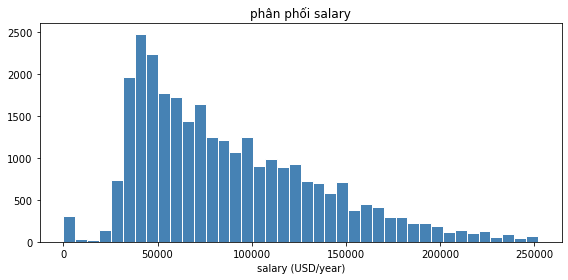

In [37]:
plt.figure(figsize=(8, 4))
plt.hist(df4["salary"].dropna(), bins=40, color="steelblue", edgecolor="white")
plt.title("phân phối salary")
plt.xlabel("salary (USD/year)")
plt.tight_layout()
plt.show()

Is salary skewed? Print skew, kurtosis, mean, median (0.6đ)
* Dùng cột salary của df4 (bỏ giá trị thiếu). Dữ liệu có lệch không? In ra skew, kurtosis, mean, median.
* Từ kurtosis, so với phân phối chuẩn thì đỉnh nhọn hơn hay hai đuôi dày hơn?

In [ ]:
s = df4["salary"].dropna()
print("skew:", s.skew())
print("kurtosis:", s.kurt())
print("mean:", s.mean())
print("median:", s.median())
#

skew: 0.8899689932377013
kurtosis: 0.31863979137135034
mean: 87343.70006426182
median: 75400.0


1. Có lệch phải ở mức vừa vì skew bằng 0.89 lớn hơn 0 nên đuôi kéo dài về phía lương cao vì mean (87343) > median(75400) lớn hơn gần 12000 . 
2. 0.32 > 0 so với phân phối chuẩn thì 2 đuôi dày hơn một chút

Gợi ý trả lời (tự điền theo số vừa in, không chép kết luận):

1. Xem dấu của skew. skew > 0 thì lệch phải, đuôi về phía giá trị lớn; skew < 0 thì lệch trái. Đối chiếu mean với median: bên nào lớn hơn thì đuôi kéo về bên đó.

2. kurtosis của pandas là excess kurtosis. Phân phối chuẩn có excess kurtosis bằng 0. Số vừa in > 0 thì đỉnh nhọn hơn và hai đuôi dày hơn chuẩn; < 0 thì đỉnh phẳng hơn và hai đuôi mỏng hơn chuẩn.

Create salary_log with np.log (0.25đ)

* Tạo cột salary_log trong df4 bằng np.log.
* salary không dương thì salary_log để NaN.
* Gợi ý: tạo cột salary_log toàn NaN trước. Dùng .loc với điều kiện salary > 0 rồi mới gán np.log. np.log chỉ nhận số dương.


In [42]:
df4 = df4.copy()
df4["salary_log"] = np.nan
mask = df4["salary"] > 0
df4.loc[mask, "salary_log"] = np.log(df4.loc[mask, "salary"])

### **Univariate Analysis (0.55đ)**


* thống kê mô tả cho 2 cột salary và salary_log trong df4 (0.3đ)

In [43]:
df4[["salary", "salary_log"]].describe()

,salary,salary_log
count,28944.000000,28935.000000
mean,87343.700064,11.169737
std,48167.177633,0.926489
min,0.000000,0.000000
25%,48599.200000,10.792526
50%,75400.000000,11.231881
75%,117083.750000,11.671125
max,252000.000000,12.437184


* In skew, kurtosis, mean, median của salary_log. Vẽ hai histogram cạnh nhau: salary và salary_log. (0.25đ)


salary_log skew: -5.303350463976039
salary_log kurtosis: 41.78904703202538
salary_log mean: 11.169737248739809
salary_log median: 11.231881180247413


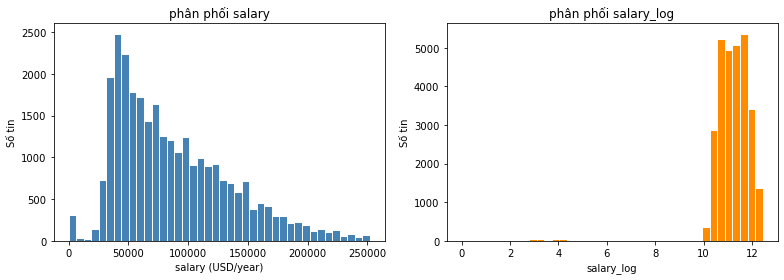

In [44]:
s_log = df4["salary_log"].dropna()

print("salary_log skew:", s_log.skew())
print("salary_log kurtosis:", s_log.kurt())
print("salary_log mean:", s_log.mean())
print("salary_log median:", s_log.median())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df4["salary"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("phân phối salary")
axes[0].set_xlabel("salary (USD/year)")

axes[1].hist(df4["salary_log"].dropna(), bins=40, color="darkorange", edgecolor="white")
axes[1].set_title("phân phối salary_log")
axes[1].set_xlabel("salary_log")

for ax in axes:
    ax.set_ylabel("Số tin")

plt.tight_layout()
plt.show()

### **Bivariate & Multivariate Analysis (1.65đ)**

Xem mối quan hệ giữa các biến.

* Heatmap (0.3đ): Correlation heatmap giữa các cột số, bao gồm views, applies, min_salary, max_salary, med_salary, salary.

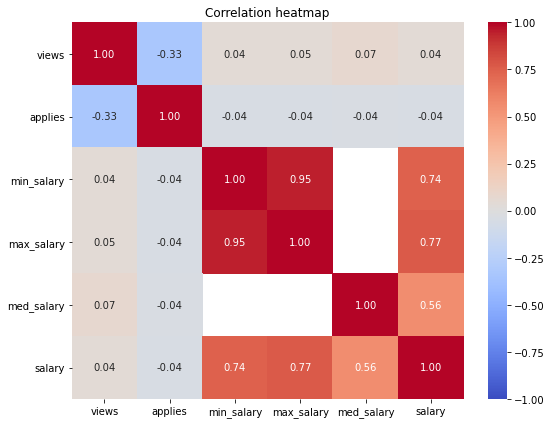

In [45]:
cols = ["views", "applies", "min_salary", "max_salary", "med_salary", "salary"]

plt.figure(figsize=(8, 6))
sns.heatmap(df4[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

* df4 group by theo formatted_work_type, tính count, mean, median của salary (0.3đ), gợi ý: .agg([count,...])


In [46]:
df4.groupby("formatted_work_type")["salary"].agg(["count", "mean", "median"])

,count,mean,median
formatted_work_type,,,
Contract,2383,93057.385898,88400.0
Full-time,23765,90175.523295,78830.0
Internship,166,50868.809880,44720.0
Other,127,71667.789449,57200.0
Part-time,2160,56893.214468,41600.0
Temporary,336,67628.729167,54437.4
Volunteer,7,20052.142857,0.0


* df4 group by theo experience_level, tính count, mean, median của salary. (0.5đ)


In [47]:
df4.groupby("experience_level")["salary"].agg(["count", "mean", "median"])

,count,mean,median
experience_level,,,
Associate,2808,78453.061521,70971.25
Director,846,158042.997051,158825.00
Entry level,8324,62687.339458,51360.40
Executive,215,150374.566488,150000.00
Internship,299,52446.171522,48880.00
Mid-Senior level,10077,105177.791091,102500.00
Unknown,6375,85392.553860,72644.00


* Tạo pivot median salary theo experience_level (hàng) và formatted_work_type (cột). Vẽ heatmap. (0.55đ). Gợi ý: dùng pivot_table, index là hàng, columns là cột, values, aggfunc gọi hàm. Sau đó vẽ heatmap


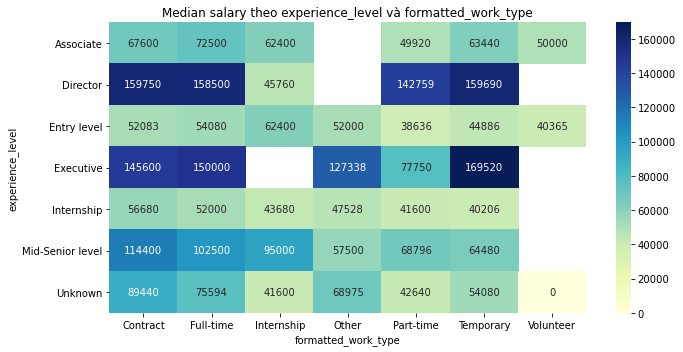

In [48]:
salary_pivot = df4.pivot_table(
    index="experience_level",
    columns="formatted_work_type",
    values="salary",
    aggfunc="median"
)

plt.figure(figsize=(10, 5))
sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Median salary theo experience_level và formatted_work_type")
plt.xlabel("formatted_work_type")
plt.ylabel("experience_level")
plt.tight_layout()
plt.show()

### **Publishing (0.35đ)**

* Lưu df4 ra file Excel, đặt tên df4.xlsx (0.2đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [49]:
cols_drop = ["description", "skills_desc", "job_posting_url", "application_url"]
df4.drop(columns=cols_drop, errors="ignore").to_excel("df4.xlsx", index=False)

* Sau đó lưu df4 ra file HTML, đặt tên df4.html (0.15đ)

Không ghi các cột description, skills_desc, job_posting_url, application_url.


In [50]:
df4.drop(columns=cols_drop, errors="ignore").to_html("df4.html", index=False)